# Coursework Question 1: Maze solver (25 marks)

Code a maze solver using the maze provided in the brief as
“maze(1).png”. The resolution of the maze is 21 squares × 21 squares,
including the outer wall. Please read the whole exercise before starting.

The entrance is at the top. Each movement must be 1 square in any
orthogonal direction (up, down, left, right): diagonal movements are
not allowed.

## Coding

a) Save the maze into an appropriate variable/data structure and
display it in your terminal.

**Hint:** Matplotlib has some interesting functions to deal with images;
you are allowed to use them if needed.

b) Ask the user what approach they want to use (Backtracking or Las Vegas).

- **b.i)** When applying a Las Vegas approach, the end conditions are
  either you found the exit (successful) or you have completed 200 steps
  without finding the exit (unsuccessful).
- **b.ii)** For the Backtracking approach, you MUST explain in the report
  what is your rationale for choosing a particular direction and how
  you do the backtracking.

c) Give a visualization of all the visited “squares” (positions) when
the program ends, regardless of if it is successful or not.

## Testing

Please add in the report between 3 and 5 instances of testing your
programme. For each testing instance, you need to create a “bug report”
with the following information:

1. What went wrong or what were you trying to fix.
2. Screenshot of the error or issue.
3. How did you fix it and why it was important to fix.

After having a complete program, please compare Las Vegas and
Backtracking approaches and answer the following questions in your report:

a) What are their differences?

b) Which data structure/s would you use to implement this problem?
Give your reasoning.

c) What is the success rate of each of the algorithms after 10000 runs?

Record yourself going over your code explaining the rationale, and
highlighting the places of the code where you fixed it.

**Hint:** To know the success rate, record which runs give a successful
result. Then, divide the successful number of runs over the total
amount of runs.


## 1. Loading the maze

Load and display it to check that it has been read correctly. Then to check its dimensions before converting it into a 21 × 21 grid.

Image shape: (210, 210, 4)


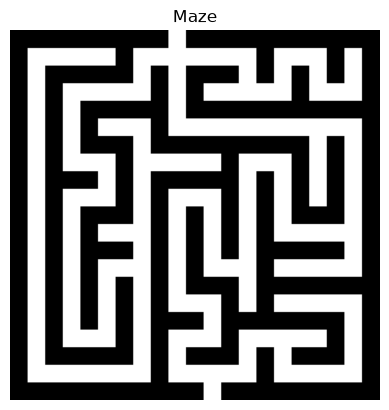

In [3]:
import matplotlib.pyplot as plt

maze_image = plt.imread("maze(1).png")
print("Image shape:", maze_image.shape)
plt.imshow(maze_image, cmap="gray")
plt.title("Maze")
plt.axis("off")
plt.show()

## 2. Convert the image into a maze grid and set up the grid

The maze contains 21 rows and 21 columns which means each square occupies 10 × 10 pixels. An empty list variable will store the completed rows.

In [8]:
maze_size = 21
square_size = 10
maze = []

The plan is to have two nested loops go through the 21 rows and columns. 

For each square, the centre pixel is read using the red colour channel. The image shape output already confirms 4 colour channels when the image was imported

Black squares are stored as walls (1), and white squares as passages (0). Each completed row is added to the maze list.

In [10]:
for row in range(maze_size):
    maze_row = []

    for column in range(maze_size):
        pixel_row = row * square_size + square_size // 2
        pixel_column = column * square_size + square_size // 2
        pixel = maze_image[pixel_row, pixel_column, 0]

        if pixel < 0.5:
            maze_row.append(1) 
        else:
            maze_row.append(0)

    maze.append(maze_row)

Need to check that the maze contains 21 rows and that every row contains 21 columns.

In [11]:
print("Number of rows:", len(maze))
correct_columns = all(len(row) == maze_size for row in maze)
print("Every row has 21 columns:", correct_columns)

Number of rows: 42
Every row has 21 columns: True


Print the maze row by row using its stored values: 1 represents a wall and 0 represents an open passage.

In [12]:
for row in maze:
    for square in row:
        print(square, end=" ")
    print()

1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 
1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1 
1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 1 
1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 
1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1 
1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 
1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 
1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 
1 0 1 1 1 1

Running the conversion cell again added another 21 rows to the existing maze list, producing 42 rows instead of 21. Need to re-do the run

In [13]:
maze = []

for row in range(maze_size):
    maze_row = []

    for column in range(maze_size):
        pixel_row = row * square_size + square_size // 2
        pixel_column = column * square_size + square_size // 2

        pixel = maze_image[pixel_row, pixel_column, 0]

        if pixel < 0.5:
            maze_row.append(1)  # Wall
        else:
            maze_row.append(0)  # Passage

    maze.append(maze_row)

In [14]:
for row in maze:
    for square in row:
        print(square, end=" ")
    print()

1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 
1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1 
1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 1 
1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 
1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1 
1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 
1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 


In [15]:
print("Number of rows:", len(maze))
print("Every row has 21 columns:",
      all(len(row) == maze_size for row in maze))

Number of rows: 21
Every row has 21 columns: True
